In [ ]:
#!python3 -m pip install pandas


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python3.11 -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

dataset_root = (Path.cwd() / "../DeepFashion2 Resized").resolve()
image_root = dataset_root / "resized"
manifest_root = dataset_root / "input"

if not dataset_root.is_dir():
    raise FileNotFoundError(
        f"DeepFashion2 dataset directory was not found: {dataset_root}. "
        "Run this notebook from the project directory and place the dataset beside it."
    )

print(f"Using DeepFashion2 data from {dataset_root}")

Using DeepFashion2 data from /Users/maithili/Desktop/ay2627/CV/project/DeepFashion2 Resized


In [3]:
def load_split(split):
    """Load image paths and detection annotations for one dataset split."""
    split_dir = image_root / split
    manifest_path = manifest_root / f"{split}.csv"
    if not split_dir.is_dir():
        raise FileNotFoundError(f"Image directory not found: {split_dir}")
    if not manifest_path.is_file():
        raise FileNotFoundError(f"Dataset manifest not found: {manifest_path}")

    samples = {}
    with manifest_path.open(newline="", encoding="utf-8") as manifest:
        reader = csv.DictReader(manifest)
        if not reader.fieldnames or "path" not in reader.fieldnames:
            raise ValueError(f"Expected a 'path' column in {manifest_path}")

        for row in reader:
            filename = Path(row["path"]).name
            image_path = split_dir / filename
            if not image_path.is_file():
                raise FileNotFoundError(f"Image listed in {manifest_path} not found: {image_path}")

            sample = samples.setdefault(
                filename, {"image_path": image_path, "annotations": []}
            )
            if row.get("category_id"):
                bbox = json.loads(row["b_box"])
                if len(bbox) != 4:
                    raise ValueError(f"Expected [x_min, y_min, x_max, y_max] for {filename}")
                sample["annotations"].append(
                    {
                        "bbox": [float(coordinate) for coordinate in bbox],
                        "category_id": int(row["category_id"]),
                        "category_name": row["category_name"],
                        "scale": int(row["scale"]),
                        "viewpoint": int(row["viewpoint"]),
                        "occlusion": int(row["occlusion"]),
                        "zoom_in": int(row["zoom_in"]),
                    }
                )

    return list(samples.values())


data_tr = load_split("train")
data_va = load_split("validation")
data_te = load_split("test")

for split_name, samples in (("train", data_tr), ("validation", data_va), ("test", data_te)):
    object_count = sum(len(sample["annotations"]) for sample in samples)
    print(f"{split_name}: {len(samples):,} images, {object_count:,} labeled items")

categories = {
    annotation["category_id"]: annotation["category_name"]
    for sample in data_tr
    for annotation in sample["annotations"]
}
print("Category IDs and names:", sorted(categories.items()))

train: 191,961 images, 312,186 labeled items
validation: 32,153 images, 52,490 labeled items
test: 62,629 images, 0 labeled items
Category IDs and names: [(1, 'short sleeve top'), (2, 'long sleeve top'), (3, 'short sleeve outwear'), (4, 'long sleeve outwear'), (5, 'vest'), (6, 'sling'), (7, 'shorts'), (8, 'trousers'), (9, 'skirt'), (10, 'short sleeve dress'), (11, 'long sleeve dress'), (12, 'vest dress'), (13, 'sling dress')]


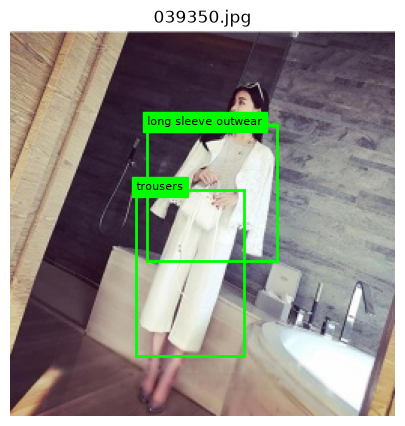

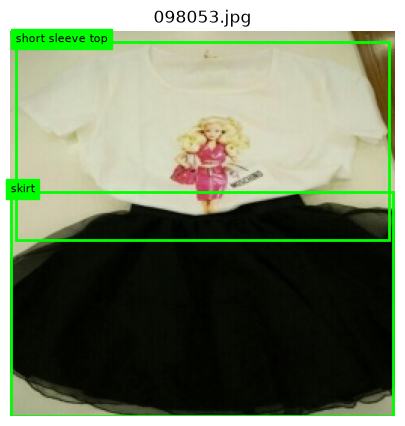

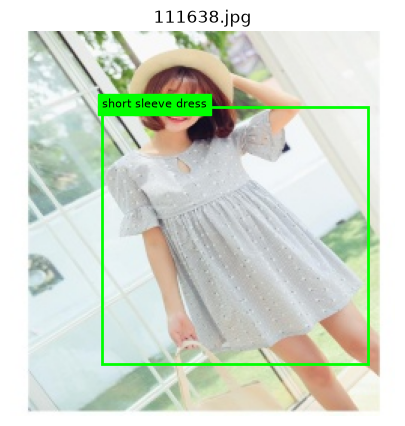

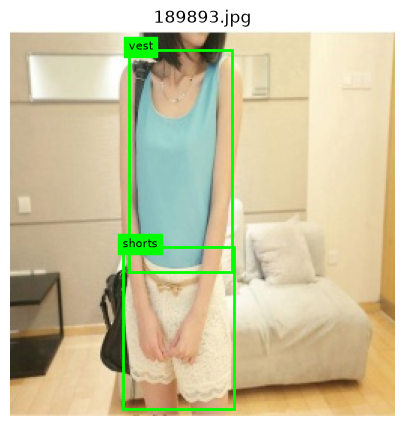

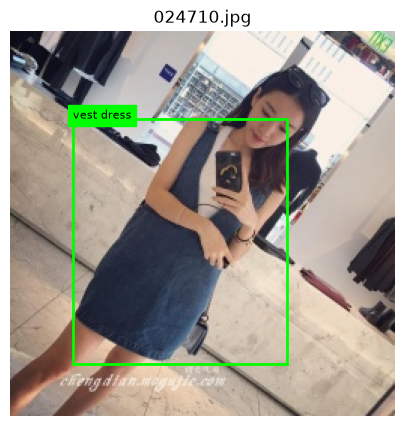

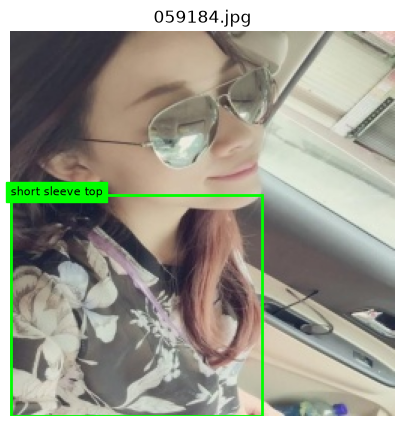

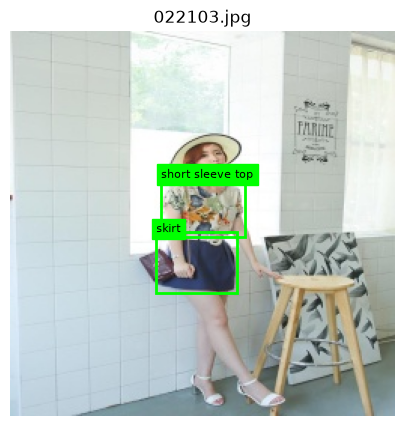

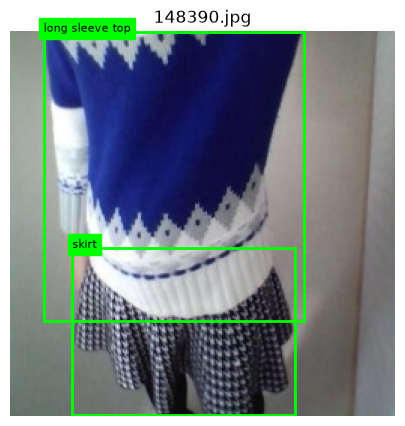

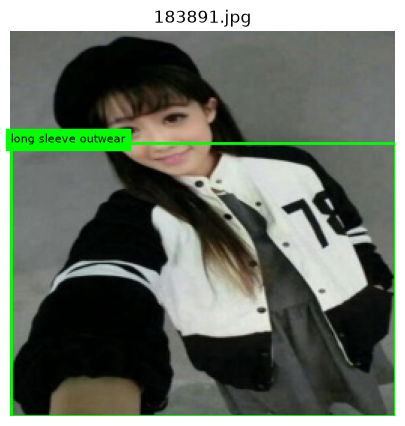

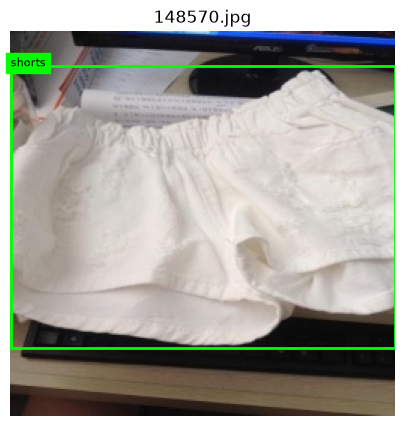

In [4]:
def show_sample(sample, ax=None):
    """Display one image with its DeepFashion2 bounding boxes and categories."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))

    image = plt.imread(sample["image_path"])
    ax.imshow(image)
    ax.set_title(sample["image_path"].name)
    ax.axis("off")

    for annotation in sample["annotations"]:
        x_min, y_min, x_max, y_max = annotation["bbox"]
        ax.add_patch(
            Rectangle(
                (x_min, y_min),
                x_max - x_min,
                y_max - y_min,
                fill=False,
                edgecolor="lime",
                linewidth=2,
            )
        )
        ax.text(
            x_min,
            y_min,
            annotation["category_name"],
            color="black",
            backgroundcolor="lime",
            fontsize=8,
        )


for sample in data_tr[:10]:
    fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
    show_sample(sample, ax=ax)
    plt.show()
    plt.close(fig)

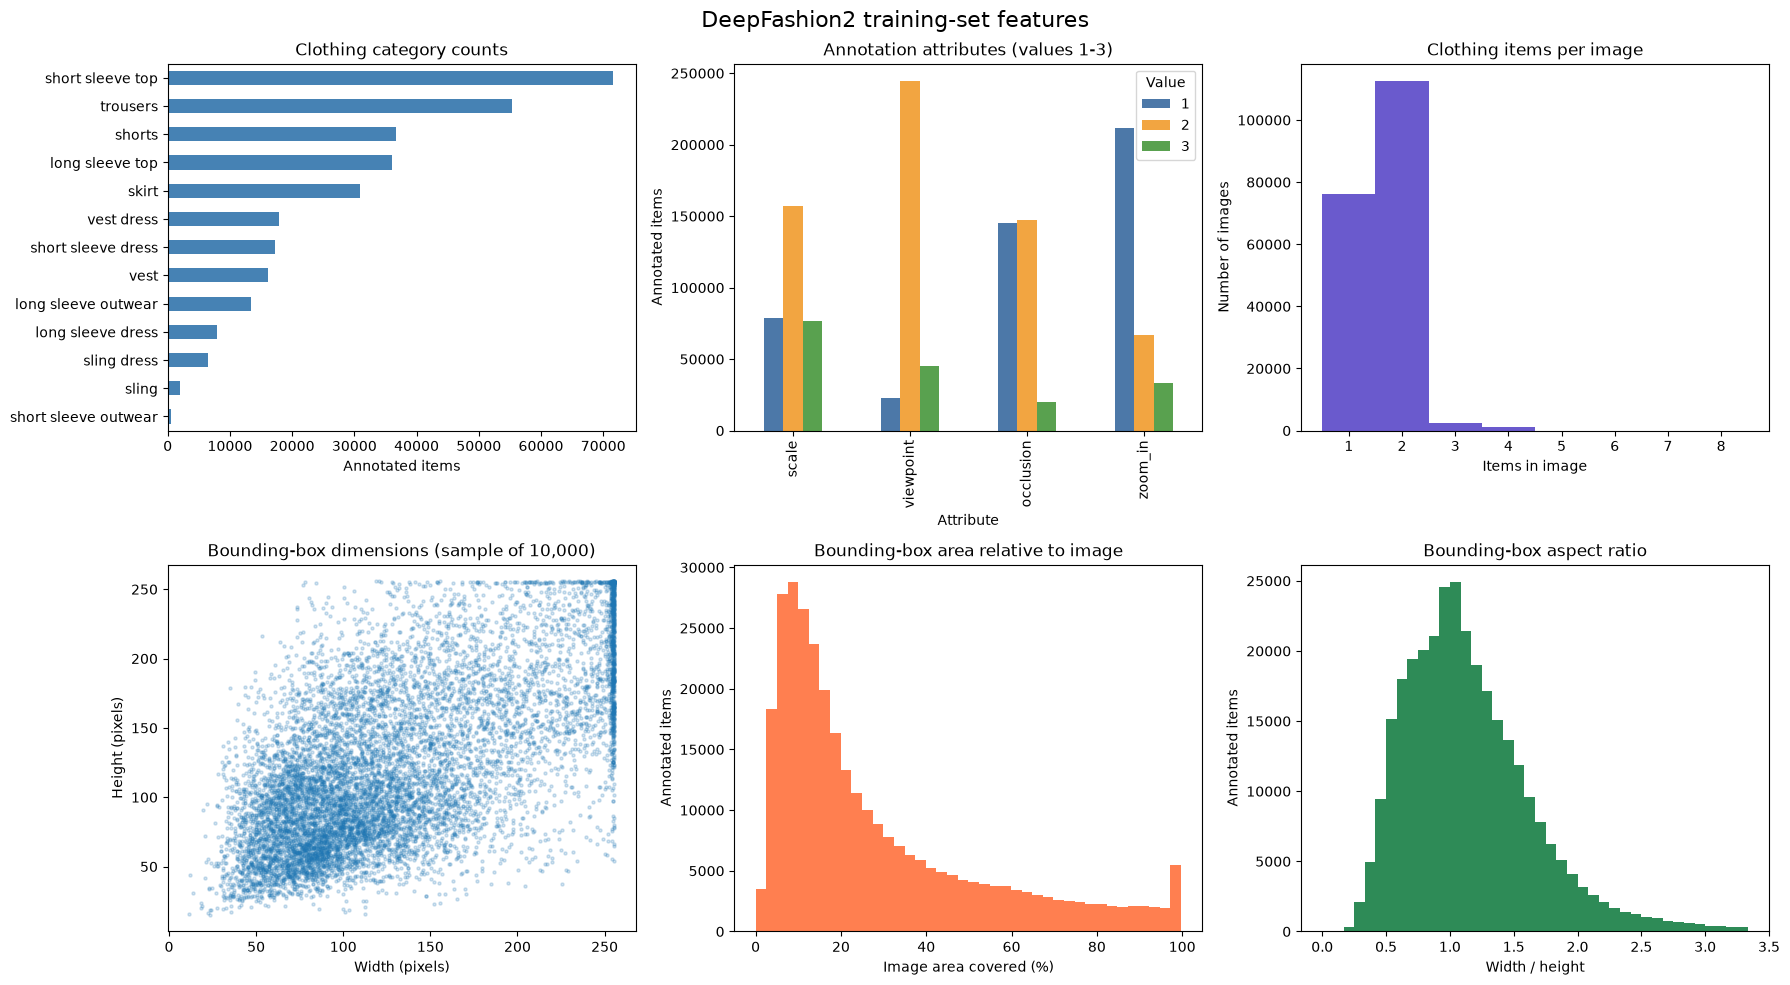

312,186 annotated items across 191,961 images


In [8]:
import numpy as np
import pandas as pd

# One row in this manifest is one clothing item; images may have multiple rows.
df = pd.read_csv(manifest_root / "train.csv")
df["image_path"] = df["path"].map(
    lambda path: image_root / "train" / Path(path).name
)
train_df = df

boxes = np.asarray(train_df["b_box"].map(json.loads).tolist(), dtype=float)
box_width = boxes[:, 2] - boxes[:, 0]
box_height = boxes[:, 3] - boxes[:, 1]
image_width = train_df["img_width"].to_numpy(dtype=float)
image_height = train_df["img_height"].to_numpy(dtype=float)
box_area_percent = (box_width * box_height) / (image_width * image_height) * 100
valid_boxes = (box_width > 0) & (box_height > 0)
box_aspect_ratio = box_width[valid_boxes] / box_height[valid_boxes]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

train_df["category_name"].value_counts().sort_values().plot.barh(
    ax=axes[0, 0], color="steelblue"
)
axes[0, 0].set(title="Clothing category counts", xlabel="Annotated items", ylabel="")

attributes = ["scale", "viewpoint", "occlusion", "zoom_in"]
attribute_counts = pd.DataFrame(
    {
        attribute: train_df[attribute].value_counts().reindex([1, 2, 3], fill_value=0)
        for attribute in attributes
    }
).T
attribute_counts.plot.bar(ax=axes[0, 1], color=["#4c78a8", "#f2a541", "#59a14f"])
axes[0, 1].set(
    title="Annotation attributes (values 1-3)",
    xlabel="Attribute",
    ylabel="Annotated items",
)
axes[0, 1].legend(title="Value")

items_per_image = train_df.groupby("path").size()
axes[0, 2].hist(
    items_per_image,
    bins=np.arange(0.5, items_per_image.max() + 1.5),
    color="slateblue",
)
axes[0, 2].set(
    title="Clothing items per image",
    xlabel="Items in image",
    ylabel="Number of images",
    xticks=range(1, int(items_per_image.max()) + 1),
)

rng = np.random.default_rng(42)
valid_indices = np.flatnonzero(valid_boxes)
sample_size = min(10_000, len(valid_indices))
sample_indices = rng.choice(valid_indices, size=sample_size, replace=False)
axes[1, 0].scatter(
    box_width[sample_indices], box_height[sample_indices], s=5, alpha=0.2
)
axes[1, 0].set(
    title=f"Bounding-box dimensions (sample of {sample_size:,})",
    xlabel="Width (pixels)",
    ylabel="Height (pixels)",
)

axes[1, 1].hist(box_area_percent, bins=40, color="coral")
axes[1, 1].set(
    title="Bounding-box area relative to image",
    xlabel="Image area covered (%)",
    ylabel="Annotated items",
)

axes[1, 2].hist(
    box_aspect_ratio,
    bins=40,
    range=(0, np.percentile(box_aspect_ratio, 99)),
    color="seagreen",
)
axes[1, 2].set(
    title="Bounding-box aspect ratio",
    xlabel="Width / height",
    ylabel="Annotated items",
)

fig.suptitle("DeepFashion2 training-set features", fontsize=16)
fig.tight_layout()
plt.show()

print(f"{len(train_df):,} annotated items across {len(items_per_image):,} images")

In [10]:
display(df.head(10))

,path,segmentation,landmarks,b_box,category_id,category_name,scale,viewpoint,occlusion,zoom_in,img_height,img_width,image_path
0,/kaggle/working/resized/train/039350.jpg,"[[144.0, 68.8, 145.6, 66.4, 148.4, 65.2, 130.0...","[387, 176, 1, 371, 163, 1, 364, 166, 1, 360, 1...","[90.80000000000001, 62.0, 176.8, 152.4]",4,long sleeve outwear,2,2,2,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
1,/kaggle/working/resized/train/039350.jpg,"[[152.4, 122.4, 133.6, 115.60000000000001, 118...","[297, 266, 1, 334, 289, 1, 381, 306, 1, 261, 3...","[83.60000000000001, 105.2, 154.8, 215.60000000...",8,trousers,2,2,2,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
2,/kaggle/working/resized/train/098053.jpg,"[[175.04273504273505, 13.388272583201267, 169....","[241, 45, 2, 172, 27, 2, 183, 78, 2, 247, 102,...","[3.2820512820512824, 6.896988906497623, 251.62...",1,short sleeve top,3,1,1,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
3,/kaggle/working/resized/train/098053.jpg,"[[82.05128205128206, 115.62599049128369, 136.2...","[150, 285, 2, 249, 302, 2, 350, 270, 2, 0, 0, ...","[0.0, 106.70047543581617, 254.3589743589744, 2...",9,skirt,3,1,1,3,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
4,/kaggle/working/resized/train/111638.jpg,"[[119.80799999999999, 68.0086393088553, 120.49...","[298, 270, 1, 242, 287, 2, 279, 302, 2, 325, 2...","[60.75733333333333, 50.31533477321815, 237.226...",10,short sleeve dress,3,2,2,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
5,/kaggle/working/resized/train/189893.jpg,"[[139.26399999999998, 149.66153846153847, 110....","[232, 300, 1, 325, 322, 2, 408, 304, 1, 222, 3...","[74.41066666666667, 143.26153846153846, 148.48...",7,shorts,2,2,2,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
6,/kaggle/working/resized/train/189893.jpg,"[[93.184, 20.184615384615384, 93.184, 41.35384...","[318, 95, 1, 273, 41, 1, 273, 84, 2, 314, 118,...","[78.50666666666666, 11.815384615384616, 147.11...",5,vest,2,2,2,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
7,/kaggle/working/resized/train/024710.jpg,"[[140.43428571428572, 62.17142857142857, 126.1...","[414, 234, 1, 384, 170, 2, 345, 257, 2, 343, 3...","[41.325714285714284, 57.78285714285714, 183.58...",12,vest dress,2,2,2,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
8,/kaggle/working/resized/train/059184.jpg,"[[115.96581196581198, 125.12820512820512, 117....","[99, 267, 1, 116, 295, 2, 154, 336, 2, 199, 38...","[0.0, 108.71794871794872, 166.83760683760684, ...",1,short sleeve top,2,2,2,2,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...
9,/kaggle/working/resized/train/022103.jpg,"[[108.4, 133.7393117831074, 127.60000000000001...","[271, 501, 1, 319, 507, 2, 354, 508, 2, 255, 5...","[96.80000000000001, 133.20542231491137, 150.4,...",9,skirt,1,2,2,1,256,256,/Users/maithili/Desktop/ay2627/CV/project/Deep...


In [11]:
df = df.drop(columns=["path", "image_path"])

In [12]:
df.head()

,segmentation,landmarks,b_box,category_id,category_name,scale,viewpoint,occlusion,zoom_in,img_height,img_width
0,"[[144.0, 68.8, 145.6, 66.4, 148.4, 65.2, 130.0...","[387, 176, 1, 371, 163, 1, 364, 166, 1, 360, 1...","[90.80000000000001, 62.0, 176.8, 152.4]",4,long sleeve outwear,2,2,2,1,256,256
1,"[[152.4, 122.4, 133.6, 115.60000000000001, 118...","[297, 266, 1, 334, 289, 1, 381, 306, 1, 261, 3...","[83.60000000000001, 105.2, 154.8, 215.60000000...",8,trousers,2,2,2,1,256,256
2,"[[175.04273504273505, 13.388272583201267, 169....","[241, 45, 2, 172, 27, 2, 183, 78, 2, 247, 102,...","[3.2820512820512824, 6.896988906497623, 251.62...",1,short sleeve top,3,1,1,1,256,256
3,"[[82.05128205128206, 115.62599049128369, 136.2...","[150, 285, 2, 249, 302, 2, 350, 270, 2, 0, 0, ...","[0.0, 106.70047543581617, 254.3589743589744, 2...",9,skirt,3,1,1,3,256,256
4,"[[119.80799999999999, 68.0086393088553, 120.49...","[298, 270, 1, 242, 287, 2, 279, 302, 2, 325, 2...","[60.75733333333333, 50.31533477321815, 237.226...",10,short sleeve dress,3,2,2,1,256,256


## train a classifier?

In [ ]:
## Train a simple binary pixel classifier

# Create a toy binary dataset: class 1 = warm colors, class 0 = cool colors
rng = np.random.default_rng(42)
class_0 = rng.normal(
    loc=[80, 110, 140],
    scale=[20, 20, 25],
    size=(200, 3),
).clip(0, 255).astype(float)
class_1 = rng.normal(
    loc=[180, 90, 60],
    scale=[25, 20, 20],
    size=(200, 3),
).clip(0, 255).astype(float)

X = np.vstack([class_0, class_1])
y = np.concatenate([np.zeros(len(class_0)), np.ones(len(class_1))])

perm = rng.permutation(len(X))
cut = int(0.8 * len(X))
train_idx = perm[:cut]
test_idx = perm[cut:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std[X_std == 0] = 1.0
X_train_n = (X_train - X_mean) / X_std
X_test_n = (X_test - X_mean) / X_std

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

w = np.zeros(X_train_n.shape[1], dtype=float)
b = 0.0
learning_rate = 0.1
n_epochs = 2000

for _ in range(n_epochs):
    z = X_train_n @ w + b
    p = sigmoid(z)
    grad_w = (X_train_n.T @ (p - y_train)) / len(X_train_n)
    grad_b = np.mean(p - y_train)
    w -= learning_rate * grad_w
    b -= learning_rate * grad_b

def predict_proba(pixel_values):
    pixel_values = np.asarray(pixel_values, dtype=float)
    pixel_values = (pixel_values - X_mean) / X_std
    p1 = sigmoid(pixel_values @ w + b)
    return np.column_stack([1.0 - p1, p1])


In [ ]:
# Evaluate the trained model
probs_test = predict_proba(X_test)
y_pred = (probs_test[:, 1] >= 0.5).astype(int)
accuracy = np.mean(y_pred == y_test)
print(f"Test accuracy: {accuracy:.3f}")

cm = np.zeros((2, 2), dtype=int)
for true, pred in zip(y_test, y_pred):
    cm[int(true), int(pred)] += 1
print("Confusion matrix:\n", cm)


In [ ]:
# Check probabilities for a few representative pixels
sample_pixels = np.array([
    [255, 120, 80],
    [10, 80, 200],
    [180, 90, 60],
    [100, 120, 150],
], dtype=float)

for pixel in sample_pixels:
    p = predict_proba(pixel.reshape(1, -1))[0]
    print(f"Pixel {pixel} -> P(class=1) = {p[1]:.3f}, P(class=0) = {p[0]:.3f}")


In [ ]:
# Plot the classifier boundary in the RGB color space (projected on the R-G plane)
blue_ref = X_mean[2]
R_vals = np.linspace(X[:, 0].min(), X[:, 0].max(), 200)
G_vals = np.linspace(X[:, 1].min(), X[:, 1].max(), 200)
R_grid, G_grid = np.meshgrid(R_vals, G_vals)
B_grid = np.full_like(R_grid, blue_ref)
points = np.column_stack([R_grid.ravel(), G_grid.ravel(), B_grid.ravel()])
probs = predict_proba(points)[:, 1].reshape(R_grid.shape)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(R_grid, G_grid, probs, levels=20, alpha=0.5, cmap="coolwarm")
ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], c="dodgerblue", s=20, label="Class 0")
ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], c="tomato", s=20, label="Class 1")
ax.set_xlabel("R")
ax.set_ylabel("G")
ax.set_title("Simple RGB pixel classifier (projected on R-G plane)")
ax.legend()
plt.show()


In [ ]:
# Quick sanity check: this flow is self-consistent
print("Pixel-classifier pipeline ready.")
print("Example output:", predict_proba(np.array([[255, 120, 80]], dtype=float))[0])


## knn..??

In [16]:
def pixel_distance(pixel_a, pixel_b):
    pixel_a = np.asarray(pixel_a, dtype=float)
    pixel_b = np.asarray(pixel_b, dtype=float)
    return np.linalg.norm(pixel_a - pixel_b)

def nearest_neighbor_proba(pixel):
    pixel = np.asarray(pixel, dtype=float).reshape(1, -1)
    distances = np.array([pixel_distance(pixel[0], train_pixel) for train_pixel in X_train])
    k = 5
    nearest = np.argsort(distances)[:k]
    p_class_1 = y_train[nearest].mean()
    return np.array([1.0 - p_class_1, p_class_1])

for pixel in np.array([[255, 120, 80], [10, 80, 200], [180, 90, 60], [100, 120, 150]], dtype=float):
    p = nearest_neighbor_proba(pixel)
    print(f"Pixel {pixel} -> P(class=1) = {p[1]:.3f}, P(class=0) = {p[0]:.3f}")


Pixel [255. 120.  80.] -> P(class=1) = 1.000, P(class=0) = 0.000
Pixel [ 10.  80. 200.] -> P(class=1) = 0.000, P(class=0) = 1.000
Pixel [180.  90.  60.] -> P(class=1) = 1.000, P(class=0) = 0.000
Pixel [100. 120. 150.] -> P(class=1) = 0.000, P(class=0) = 1.000


In [18]:
# Evaluate the trained binary pixel classifier on the held-out test set
probs_test = predict_proba(X_test)
y_pred = (probs_test[:, 1] >= 0.5).astype(int)
accuracy = np.mean(y_pred == y_test)
print(f"Binary pixel classifier accuracy: {accuracy:.3f}")

cm = np.zeros((2, 2), dtype=int)
for true_label, pred_label in zip(y_test, y_pred):
    cm[int(true_label), int(pred_label)] += 1
print("Confusion matrix:\n", cm)


Binary pixel classifier accuracy: 1.000
Confusion matrix:
 [[31  0]
 [ 0 49]]


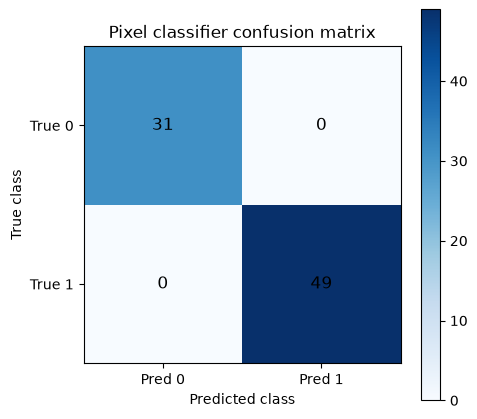

In [19]:
# Plot the confusion matrix for the RGB pixel classifier
plt.figure(figsize=(5, 4.5))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["Pred 0", "Pred 1"])
plt.yticks([0, 1], ["True 0", "True 1"])
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Pixel classifier confusion matrix")
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", color="black", fontsize=12)
plt.colorbar()
plt.tight_layout()
plt.show()
